In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import logging
import random
from copy import deepcopy
import re
from sklearn.metrics import mean_squared_error, root_mean_squared_error

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import torch
import numpy as np
from dotenv import load_dotenv
from natsort import natsorted
from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

In [2]:
def parse_condition(condition: str) -> tuple[tuple[str, ...], str]:
    """Split a condition string into knocked-out genes and environment."""
    ko_part, _, env_part = condition.partition(". Env: ")
    ko_genes = tuple(re.findall(r"Node_\d+", ko_part.replace("KO: ", "")))
    return ko_genes, env_part or "None"


def compute_gene_level_double_ko_epistasis(df: pd.DataFrame) -> pd.DataFrame:
    """For each gene, compare the double-KO trajectory to both single-KO trajectories and keep the strongest match."""
    wide_df = df.pivot_table(
        index=[DfColumnNames.TIME_COL],
        columns=[DfColumnNames.GENE_COL, DfColumnNames.CONDITION_COL],
        values=DfColumnNames.GROUND_TRUTH_COL,
        aggfunc="first",
    )

    rows = []
    conditions = list(df[DfColumnNames.CONDITION_COL].unique())
    genes = sorted(df[DfColumnNames.GENE_COL].unique())

    for condition in sorted(conditions):
        ko_genes, env_name = parse_condition(condition)

        if len(ko_genes) != 2:
            continue

        matching_single_conditions = []
        for single_gene in ko_genes:
            matching_single_condition = next(
                (
                    candidate
                    for candidate in conditions
                    if parse_condition(candidate)[0] == (single_gene,)
                    and parse_condition(candidate)[1] == env_name
                ),
                None,
            )
            if matching_single_condition is not None:
                matching_single_conditions.append(matching_single_condition)

        for gene_name in genes:
            if (gene_name, condition) not in wide_df.columns:
                continue

            single_mses = []
            for single_condition in matching_single_conditions:
                if (gene_name, single_condition) not in wide_df.columns:
                    continue

                double_series = wide_df[(gene_name, condition)]
                single_series = wide_df[(gene_name, single_condition)]

                comparison = pd.concat(
                    [
                        double_series.rename("double_ko"),
                        single_series.rename("single_ko"),
                    ],
                    axis=1,
                ).dropna()

                mse = root_mean_squared_error(comparison["double_ko"], comparison["single_ko"])
                single_mses.append((mse, single_condition))

            lowest_mse, best_single_condition = min(
                single_mses,
                key=lambda item: item[0],
            )
            rows.append(
                {
                    'condition': condition,
                    "double_ko": ", ".join(ko_genes),
                    "gene": gene_name,
                    "best_single_ko_condition": best_single_condition,
                    "single-to-double-ko-divergence": lowest_mse
                }
            )

    return pd.DataFrame(rows).sort_values("single-to-double-ko-divergence", ascending=False)


Just have to get the simulation run of the 50 gene network I suppose

In [3]:
records = []
run_ids = ['70758f132a104c7b9260d309b738594a']
for run_id in run_ids:
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    epistasis_df = compute_gene_level_double_ko_epistasis(long_form_simulation)
    epistasis_df['nr_genes'] = mlflow.get_run(run_id).data.params['nr_genes']
    records.append(epistasis_df)
full_df = pd.concat(records, ignore_index=True)

full_df.to_csv('epistasis_levels_disconnected_modules.csv', index=False)

2026-07-13 16:48:54,722 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-13 16:48:54,729 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-13 16:48:54,769 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-13 16:48:54,780 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-13 16:48:54,787 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-13 16:48:54,790 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-13 16:48:54,801 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-13 16:48:54,814 - WARNING - Connection p

In [4]:
full_df['nr_genes'].value_counts()

nr_genes
50    2500
Name: count, dtype: int64

In [5]:
epistasis_df.sort_values('single-to-double-ko-divergence', ascending=False).head(10)

,condition,double_ko,gene,best_single_ko_condition,single-to-double-ko-divergence,nr_genes
2417,"KO: Node_6, Node_8. Env: None","Node_6, Node_8",Node_24,KO: Node_6. Env: None,0.279941,50
1770,"KO: Node_3, Node_38. Env: None","Node_3, Node_38",Node_27,KO: Node_38. Env: None,0.192027,50
1858,"KO: Node_31, Node_40. Env: None","Node_31, Node_40",Node_16,KO: Node_31. Env: None,0.179178,50
1908,"KO: Node_31, Node_48. Env: None","Node_31, Node_48",Node_16,KO: Node_31. Env: None,0.176801,50
2208,"KO: Node_4, Node_34. Env: None","Node_4, Node_34",Node_16,KO: Node_4. Env: None,0.176732,50
1638,"KO: Node_27, Node_32. Env: None","Node_27, Node_32",Node_43,KO: Node_27. Env: None,0.175398,50
88,"KO: Node_10, Node_39. Env: None","Node_10, Node_39",Node_43,KO: Node_39. Env: None,0.174837,50
358,"KO: Node_12, Node_18. Env: None","Node_12, Node_18",Node_16,KO: Node_18. Env: None,0.174596,50
819,"KO: Node_17, Node_30. Env: None","Node_17, Node_30",Node_26,KO: Node_30. Env: None,0.174246,50
408,"KO: Node_12, Node_22. Env: None","Node_12, Node_22",Node_16,KO: Node_22. Env: None,0.174198,50


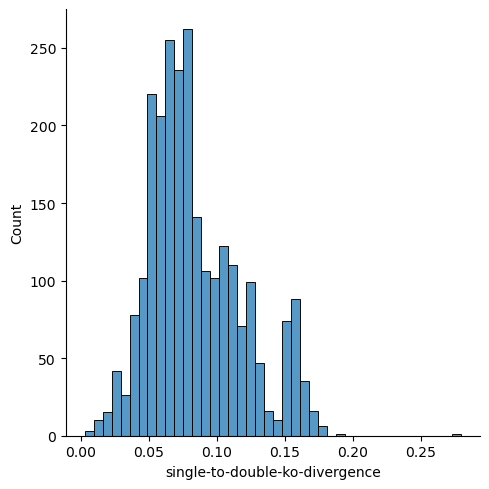

In [6]:
sns.displot(epistasis_df, x='single-to-double-ko-divergence')

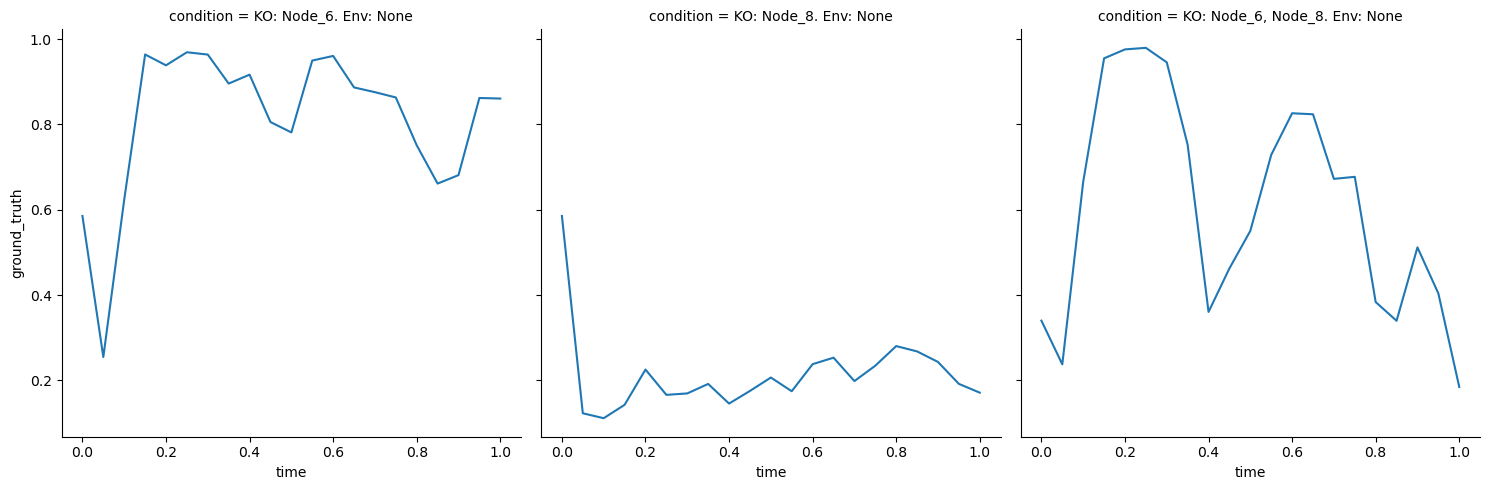

In [7]:
double_ko_str = 'KO: Node_6, Node_8. Env: None'
gene_str = 'Node_24'
single_ko_1_str = 'KO: Node_6. Env: None'
single_ko_2_str = 'KO: Node_8. Env: None'


a = long_form_simulation[
    ((long_form_simulation[DfColumnNames.CONDITION_COL] == double_ko_str) 
     | (long_form_simulation[DfColumnNames.CONDITION_COL] == single_ko_1_str)
     | (long_form_simulation[DfColumnNames.CONDITION_COL] == single_ko_2_str)) 
     & (long_form_simulation[DfColumnNames.GENE_COL] == gene_str) ]
# a
sns.relplot(data=a, x='time', y='ground_truth', col='condition', kind='line')

In [8]:
connected_modules_divergence_df = pd.read_csv('epistasis_levels.csv')
connected_modules_divergence_df.loc[:, 'modules_connected'] = True

In [9]:
epistasis_df['modules_connected'] = False

In [10]:
subset_connected = connected_modules_divergence_df[connected_modules_divergence_df['nr_genes'] == 50]

In [11]:
combined_df = pd.concat([epistasis_df, subset_connected], ignore_index=True)
combined_df['modules_connected'].value_counts()

modules_connected
False    2500
True     2500
Name: count, dtype: int64

In [12]:
combined_df.groupby('modules_connected')['single-to-double-ko-divergence'].apply(lambda x: (x > 0.2).sum())

modules_connected
False     1
True     10
Name: single-to-double-ko-divergence, dtype: int64

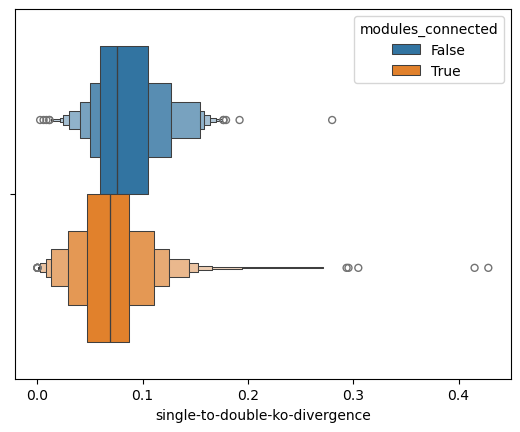

In [18]:
sns.boxenplot(combined_df, x='single-to-double-ko-divergence', hue='modules_connected')
plt.savefig("divergence_50_genes_connected_or_not.pdf", dpi=600, bbox_inches='tight')